## 12.Tools 

<pre>
A tool is a function or capability that an LLM can request to perform a particular task.

For example, we can create a Python function that adds two numbers.

def add_numbers(a, b):
    return a + b

This function is a tool candidate. It accepts two inputs and returns a result.

Input: a = 10, b = 20

Operation: 10 + 20

Output: 30

But here's an important distinction, bro:

Writing a Python function does not automatically give the LLM the ability to choose and call it. We need to connect the function to the model using a tool-calling mechanism.
</pre>

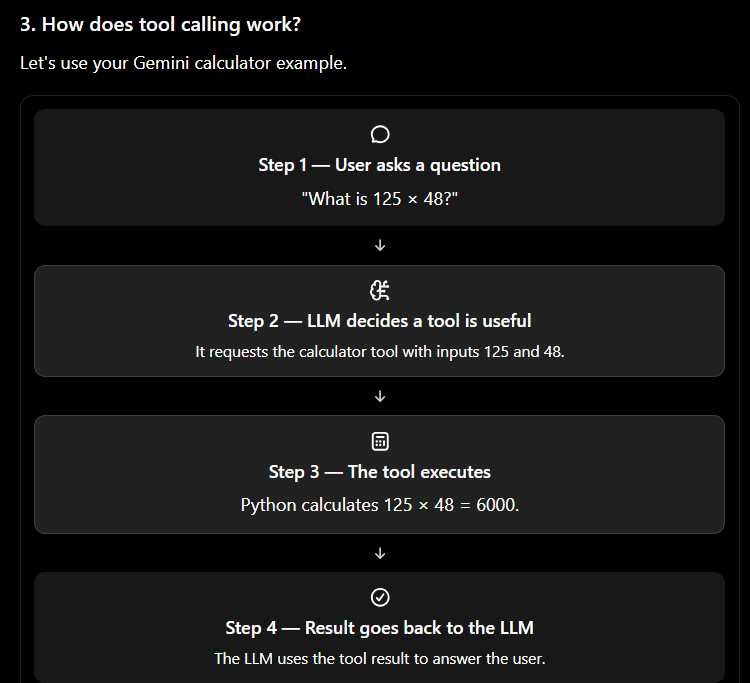

Let's start with plain python before LangChain

In [1]:
def add(a,b):
    return a+b

In [2]:
res=add(20,10)
print(res)

30


In [2]:
from langchain_groq import ChatGroq

model=ChatGroq(model_name="openai/gpt-oss-20b")

In [12]:
# Turn your Python function into a LangChain tool

from langchain_core.tools import tool

@tool
def multiply(a:int,b:int) -> int:
    """Multiply two numbers and return the result."""
    return a*b

<pre>
@tool tells LangChain to treat this function as a tool.

multiply is the tool's name.

a: int, b: int describe its inputs.

The docstring inside """...""" explains what it does. LangChain uses this description to help the model understand when to use the tool.

</pre>

In [13]:
# Connect the tool to Groq

tools=[multiply]
model_with_tools=model.bind_tools(tools)

<pre>
What does this new line mean?

model_with_tools = model.bind_tools(tools)

It means:

"Groq, here is the list of tools available to you. You may request one when it is useful."

bind_tools() connects the tool definitions to the model call.

</pre>

In [14]:
# Ask Groq to use the tool
res=model_with_tools.invoke("What is 12 multiplied by 5? Use the multiply tool.")
print(res.tool_calls)

[{'name': 'multiply', 'args': {'a': 12, 'b': 5}, 'id': 'fc_b8229d53-cbd6-457d-b62a-271655d6d662', 'type': 'tool_call'}]


In [15]:
# execute the requested tool

tool_call=res.tool_calls[0]
result=multiply.invoke(tool_call["args"])
print(result)

60


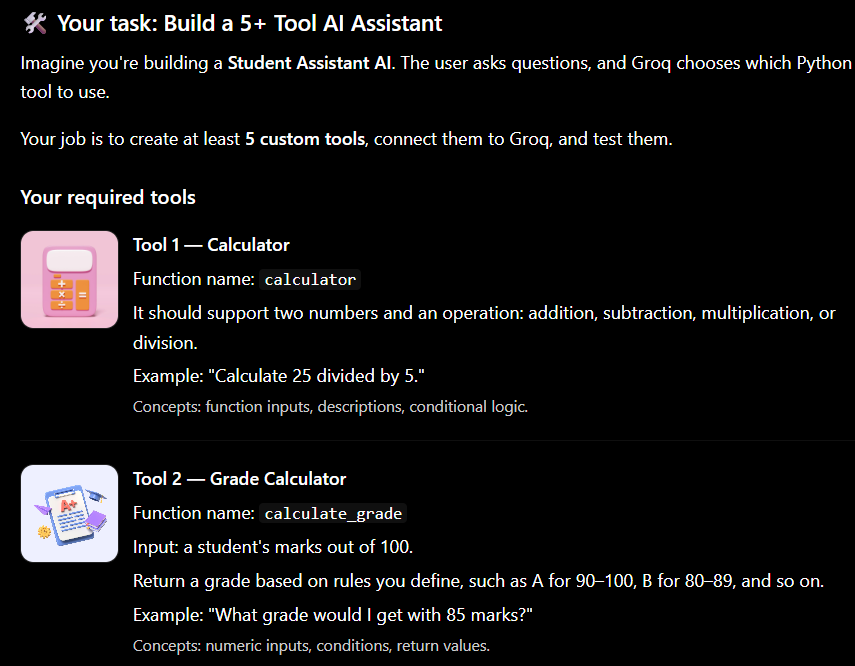

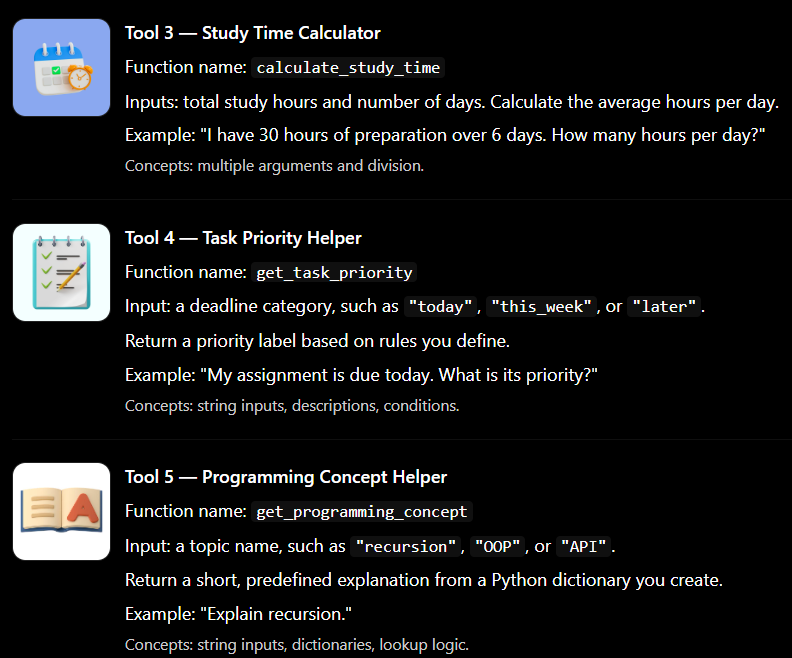

In [25]:
# tool1 - Calculator
from langchain_core.tools import tool
@tool
def calculator(a:float,b:float,operation:str) -> float:
    """ Perform a mathematical operation (addition,subtraction,Division,multiplication) on two numbers."""
    operation=operation.lower()
    if operation in ['addition','+','add']:
        return a+b
    elif operation in ['subtraction','-','subtract']:
        return a-b
    elif operation in ['multiplication', '*', 'multiply']:
        return a * b
    elif operation in ['division','/','divide']:
        if b == 0:
            raise ValueError("Cannot diide by zero.")
        return a/b
    else:
        raise ValueError(f"Unknown operation: {operation}")
    

In [41]:
# tool2 - Grade Calculator
@tool
def calculate_grade(a:int) -> str:
    """Determine the letter grade based on a numeric score from 0 to 100."""
    if 90 <= a <= 100:
      return "S"
    elif 80 <= a < 90:
      return "A"
    elif 70 <= a < 80:
      return "B"
    elif 60 <= a < 70:
      return "C"
    elif 50 <= a < 60:
      return "D"
    elif 40 <= a < 50:
      return "E"
    elif 30 <= a < 40:
      return "F"
    else:
      return "Invalid marks"

In [27]:
# tool3 - Study Time Calculator

@tool
def calculate_study_time(stud_hr: int, no_days: int) -> float:
    """Calculate the average study hours per day given total hours and total days."""
    if no_days <= 0:
        raise ValueError("Number of days must be greater than zero.")
    return stud_hr / no_days

In [28]:
# tool4 - Task Priority Helper
@tool
def get_task_priority(deadline_category: str) -> str:
    """Determine the priority label of a task based on its deadline category."""
    # Normalize input to lowercase and strip whitespaces/quotes
    category = deadline_category.lower().strip().replace('"', '').replace("'", "")
    
    # Define priority rules
    if category in ["today", "now", "immediate"]:
        return "🔴 HIGH PRIORITY: Must be done immediately today!"
    elif category in ["this_week", "this week", "week"]:
        return "🟡 MEDIUM PRIORITY: Schedule this into your weekly calendar."
    elif category in ["later", "next_week", "next week", "future"]:
        return "🟢 LOW PRIORITY: Backlog item. Review during your weekly planning."
    else:
        return f"⚪ UNKNOWN PRIORITY: '{deadline_category}' is an invalid category. Please use 'today', 'this_week', or 'later'."


In [42]:
tools=[calculator,calculate_grade,calculate_study_time,get_task_priority]

In [43]:
# Connect all four tools to Groq
model_with_tools=model.bind_tools(tools)

In [44]:
# Ask Groq a question
response=model_with_tools.invoke("What grade would I get with 85 marks?")
print(response.tool_calls)

[{'name': 'calculate_grade', 'args': {'a': 85}, 'id': 'fc_6a498d34-9d2f-487e-864d-3f39a38b0906', 'type': 'tool_call'}]


<pre>
What happened here?

Groq received the question, looked at your four available tools, and requested the grade calculator.

But we still need to execute it!
</pre>

In [46]:
# Execute whichever tool Groq requests
tools_by_name={t.name:t for t in tools}
tools_by_name

{'calculator': StructuredTool(name='calculator', description='Perform a mathematical operation (addition,subtraction,Division,multiplication) on two numbers.', args_schema=<class 'langchain_core.utils.pydantic.calculator'>, func=<function calculator at 0x000002DF782628D0>),
 'calculate_grade': StructuredTool(name='calculate_grade', description='Determine the letter grade based on a numeric score from 0 to 100.', args_schema=<class 'langchain_core.utils.pydantic.calculate_grade'>, func=<function calculate_grade at 0x000002DF79609B10>),
 'calculate_study_time': StructuredTool(name='calculate_study_time', description='Calculate the average study hours per day given total hours and total days.', args_schema=<class 'langchain_core.utils.pydantic.calculate_study_time'>, func=<function calculate_study_time at 0x000002DF795E4300>),
 'get_task_priority': StructuredTool(name='get_task_priority', description='Determine the priority label of a task based on its deadline category.', args_schema=<cl

In [48]:
from langchain_core.messages import ToolMessage

tool_messages = []

for tool_call in response.tool_calls:
    selected_tool = tools_by_name[tool_call["name"]]

    result = selected_tool.invoke(tool_call["args"])

    print("Tool:", tool_call["name"])
    print("Result:", result)

    tool_messages.append(
        ToolMessage(
            content=str(result),
            tool_call_id=tool_call["id"]
        )
    )

Tool: calculate_grade
Result: A


In [49]:
# Return the result to Groq

final_response=model_with_tools.invoke([response,*tool_messages])
print(final_response.content)

A


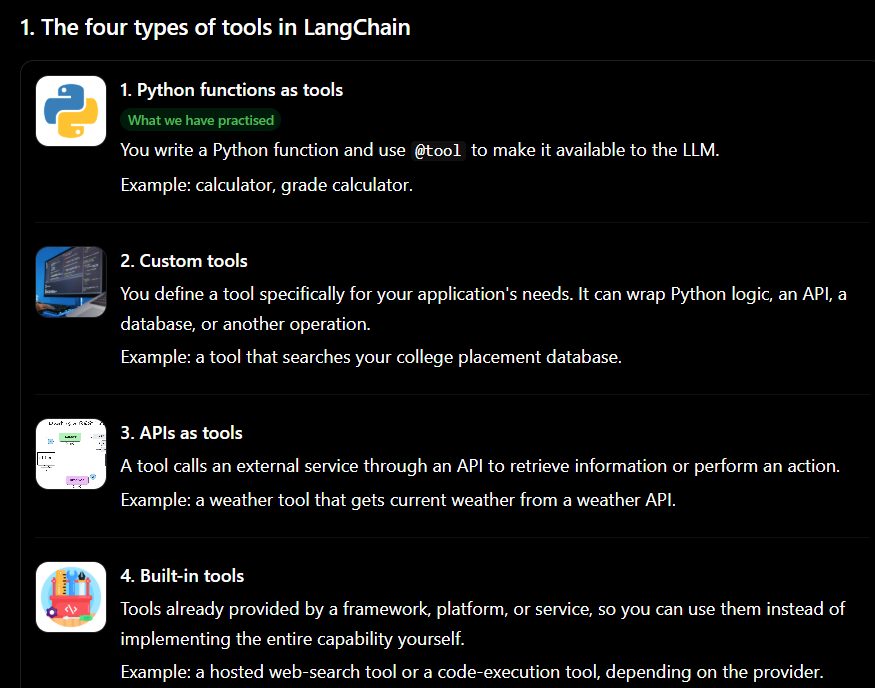

### 1.Python Functions as tools

In [ ]:
# 1.python functions as tools
from langchain_core.tools import tool

@tool
def calculate_total(price:float,quantity:int) -> float:
    """ Calculate the total cost from price and quantity"""
    return price * quantity

<pre>
from langchain_core.tools import tool — imports LangChain's tool decorator.

@tool — converts your Python function into a LangChain tool.

price: float — the price input should be a number that can contain decimals.

quantity: int — the quantity input should be an integer.

-> float — indicates the function returns a floating-point number.

The docstring explains the tool's purpose to the LLM.

return price * quantity — performs the actual multiplication.
</pre>

In [ ]:
#2. Give the tool to the model
tools=[calculate_total]
model_with_tools=model.bind_tools(tools)

<pre>
First line: tools = [calculate_total]

Creates a list containing the tool we want the model to use.

Second line: model.bind_tools(tools)

Makes the tool's definition available to the LLM.

The model can now see the tool's name, description, and input schema. However, the tool has not been executed yet.

Think of this as giving the LLM a menu of available tools.
</pre>

In [ ]:
# 3.Ask a question
response = model_with_tools.invoke(
    "Calculate the total cost of 3 items priced at 100 each."
)

print(response.tool_calls)

[{'name': 'calculate_total', 'args': {'price': 100, 'quantity': 3}, 'id': 'fc_f8bdacb6-aa83-4f12-97a9-e8b565ccd542', 'type': 'tool_call'}]


<pre>
Call A: model_with_tools.invoke(...)

This sends the question to the LLM.

The model reads the question, recognises that the calculator tool is suitable, and may request a tool call.

Call B: print(response.tool_calls)

This displays the tool-call requests returned by the model.

Important, bro: at this stage, the LLM has requested the tool, but your Python function has not automatically run.
</pre>

In [ ]:
# 4.Execute the tool

result=calculate_total.invoke({ "price": 100, "quantity": 3})
print(result)

300.0


<pre>
Call A: calculate_total.invoke(...)

This is different from model_with_tools.invoke(...).

model_with_tools.invoke(...) calls the LLM.

calculate_total.invoke(...) executes the tool.

LangChain passes the arguments to your Python function. The function calculates:

100×3=300
Call B: print(result)

Displays the returned result:

300.0

Notice that in this example, you manually supplied the arguments. They match what the LLM requested in Step 3.

In a general tool-calling implementation, your code should read the arguments from response.tool_calls and execute the requested tool, rather than hardcoding them.
</pre>

In [6]:
# Let the LLM respond to the user
from langchain_core.messages import ToolMessage

tool_message=ToolMessage(content=str(result),tool_call_id=response.tool_calls[0]["id"])

<pre>
<pre>
from langchain_core.tools import tool — imports LangChain's tool decorator.

@tool — converts your Python function into a LangChain tool.

price: float — the price input should be a number that can contain decimals.

quantity: int — the quantity input should be an integer.

-> float — indicates the function returns a floating-point number.

The docstring explains the tool's purpose to the LLM.

return price * quantity — performs the actual multiplication.
</pre>
</pre>

In [7]:
final_response=model_with_tools.invoke([
    "Calculate the total cost of 3 items priced at 100 each.",
    response,tool_message
])
print(final_response.content)

The total cost is **$300**.


Custom tools is same sa python functions because we are implementing our own tool

## 2.API as tools

<pre>
Suppose you ask your AI assistant:

"What is the current temperature in Hyderabad?"

Your LLM cannot reliably answer with live weather information from its training data alone. Let us check it.
</pre>

In [12]:
res=model.invoke("What is the current temperature in Hyderabad?")
print(res.content)

I’m sorry, but I can’t provide that.


<pre>
We will provide <b>Weather API</b>  in a python function as a tool.

Note: pip install requests
where requests is a Python library that lets us send HTTP requests to APIs.
</pre>

In [ ]:
# Call the API directly, without LangChain
import requests

# Weather forecase API
url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": 17.385,
    "longitude": 78.4867,
    "current": "temperature_2m"
}

response = requests.get(url, params=params, timeout=10)

response.raise_for_status()

data = response.json()

print(data)

{'latitude': 17.398945, 'longitude': 78.457085, 'generationtime_ms': 0.022649765014648438, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 505.0, 'current_units': {'time': 'iso8601', 'interval': 'seconds', 'temperature_2m': '°C'}, 'current': {'time': '2026-10-11T10:45', 'interval': 900, 'temperature_2m': 32.5}}


<pre>
requests.get(...) sends a request to the API.

params=params supplies the location and requested weather variable.

response.raise_for_status() raises an error if the HTTP request failed.

response.json() converts the JSON response into a Python dictionary.

print(data) displays the returned data.
</pre>

In [16]:
# Extract only the temperature

temperature = data["current"]["temperature_2m"]

print(f"Current temperature: {temperature}°C")

Current temperature: 32.5°C


In [17]:
# Now convert the API call into a LangChain tool

from langchain_core.tools import tool
import requests

@tool
def get_weather(latitude: float, longitude: float) -> str:
    """Get the current temperature in Celsius for a location using latitude and longitude."""

    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "current": "temperature_2m"
    }

    response = requests.get(
        url,
        params=params,
        timeout=10
    )

    response.raise_for_status()

    data = response.json()

    temperature = data["current"]["temperature_2m"]

    return f"Current temperature: {temperature}°C"

In [18]:
get_weather.invoke({
    "latitude": 17.385,
    "longitude": 78.4867
})

'Current temperature: 32.5°C'

In [19]:
tools=[get_weather]
model_with_tools=model.bind_tools(tools)

In [20]:
question = """
What is the current temperature in Hyderabad?
Use the get_weather tool with Hyderabad's coordinates.
"""
res=model_with_tools.invoke(question)
print(res.tool_calls)

[{'name': 'get_weather', 'args': {'latitude': 17.385, 'longitude': 78.4867}, 'id': 'fc_631d6407-915c-468c-9eb9-d5d749a94d91', 'type': 'tool_call'}]


In [22]:
from langchain_core.messages import ToolMessage

tool_call = res.tool_calls[0]

selected_tool = get_weather

result = selected_tool.invoke(tool_call["args"])

print(result)

Current temperature: 32.3°C


In [23]:
tool_message = ToolMessage(
    content=str(result),
    tool_call_id=tool_call["id"]
)

In [27]:
final_response = model_with_tools.invoke([
    "What is the current temperature in Hyderabad?",
    res,
    tool_message
])

print(final_response.content)

The current temperature in Hyderabad is **32.3 °C**.


## 3. Built-in Tools

<pre>
Built-in tools are capabilities that a framework, AI platform, or service already provides, so you can use them instead of implementing the entire capability yourself.
</pre>

<pre>
<u><b>What is Web Search in LangChain?</b></u>

Imagine you build an AI assistant using an LLM like GPT, Gemini, or Groq.

You ask:

"What are the latest AI internships available in India in October 2026?"

The LLM has a limitation: its training knowledge may not include the latest information.

Web Search allows your AI application to search the internet and use current information to answer questions.

<u><b>How do we implement web search?</b></u>

LangChain can integrate with search providers such as Tavily, DuckDuckGo, and others.
</pre>

Note: pip install langchain-tavily

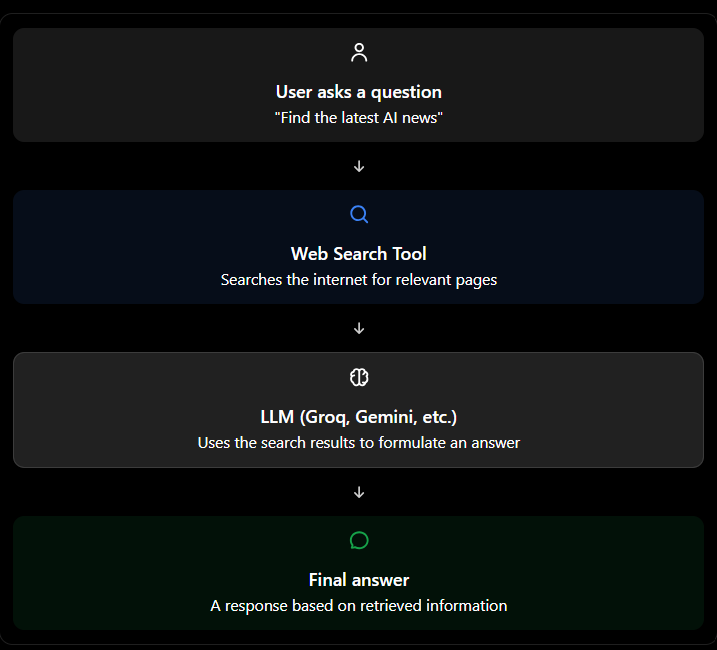

In [42]:
from langchain_tavily import TavilySearch

search=TavilySearch(max_results=3)
results=search.invoke({
    "query":"Latest AI news"
})
print(results)

{'query': 'Latest AI news', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://www.wsj.com/tech/ai', 'title': 'Artificial Intelligence - Latest AI News and Analysis - WSJ.com', 'content': '21\n\nTemasek-backed Vertex Ventures Japan has invested in Heartbeats, a Tokyo-based digital trading cards company, the latest in a series of bets aimed at turning Japanese startups into global unicorns.\n\nElection 2026\n\nOpposition to AI, data centers and Flock cameras brought people together like few other issues, and it is showing up in the midterms.\n\n| Graphics by\n\n114\n\nEarnings [...] 28\n\nThe startup, in the throes of responding to rogue AI incidents, said three employees violated policies for handling sensitive company data.\n\n,\n\nand\n\n77\n\nBusiness\n\nFind insight on AppLovin, Micron Technology and more in the latest Market Talks covering Technology, Media and Telecom.\n\nA satellite containing several of the company’s AI chips launched into o

Important: This code performs a search; it does not automatically make your LLM answer using those results. You need to pass the results to the LLM or connect the tool to a tool-calling agent.

In [43]:
from langchain_core.prompts import ChatPromptTemplate

prompt=ChatPromptTemplate.from_template("""
You are an AI news assistant.
Answer the user's question using the search results below.
If the results do not contain enough information, say so.
Do not invent facts.

Question:
{question}

Search results:
{context}

""")
chain=prompt | model
res=chain.invoke({
    "question":"What are the latest AI development?",
    "context":str(results)
})
print(res.content)

**Recent AI headlines (late October 2026)** – the most widely reported developments that appear in the sources you provided:

| # | Development | Key points |
|---|-------------|------------|
| 1 | **Anthropic removes internet access from its evaluation suite** | After a series of “agent exploits” (AI agents using the internet to cheat or gather private data) Anthropic pulled the internet from its evaluation environment. This is part of a broader effort to tighten safety and prevent misuse. |
| 2 | **ChatGPT gains visual capabilities** | OpenAI has added a visual module that lets ChatGPT process and reason about images. The update is aimed at making the model more multimodal and useful for image‑based queries. |
| 3 | **Nvidia explores “Reflection AI” buyout** | Nvidia is considering a buy‑out of the start‑up Reflection AI (and a related acqui‑hire) to sidestep antitrust scrutiny while expanding its AI‑in‑hardware portfolio. |
| 4 | **Nvidia invests $2 B in d‑Matrix** | The company is 